In [1]:
using Plots
using LaTeXStrings

In [2]:
using LinearAlgebra: BLAS
using Distributed

BLAS.set_num_threads(1)
addprocs(7, exeflags=["--project"], enable_threaded_blas=false);

In [3]:
gr();
# pyplot();
# plotlyjs();

In [4]:
# Load in parent process first in case recompilation is needed
using Revise
using ComplexSpectralDensities

In [5]:
@everywhere workers() using Revise
@everywhere workers() using ComplexSpectralDensities

In [6]:
include("example_problems.jl")

circulant_from_jordan (generic function with 1 method)

In [7]:
N_full = 900
N = 30

λ = 0.0
σ = 0.8
τ = 0.5

ensemble_full = jordan(N_full, N_full, λ, σ, τ)
ensemble = jordan(N, N, λ, σ, τ)

# ensemble_full.T .= repeat(sqrt.([0.7; 0.5; 0.3]), N_full ÷ 3)
# ensemble.T .= repeat(sqrt.([0.7; 0.5; 0.3]), N ÷ 3)

ensemble.M

30×30 Bidiagonal{Complex{Float64},Array{Complex{Float64},1}}:
 0.0+0.0im  1.0+0.0im      ⋅      …      ⋅          ⋅          ⋅    
     ⋅      0.0+0.0im  1.0+0.0im         ⋅          ⋅          ⋅    
     ⋅          ⋅      0.0+0.0im         ⋅          ⋅          ⋅    
     ⋅          ⋅          ⋅             ⋅          ⋅          ⋅    
     ⋅          ⋅          ⋅             ⋅          ⋅          ⋅    
     ⋅          ⋅          ⋅      …      ⋅          ⋅          ⋅    
     ⋅          ⋅          ⋅             ⋅          ⋅          ⋅    
     ⋅          ⋅          ⋅             ⋅          ⋅          ⋅    
     ⋅          ⋅          ⋅             ⋅          ⋅          ⋅    
     ⋅          ⋅          ⋅             ⋅          ⋅          ⋅    
     ⋅          ⋅          ⋅      …      ⋅          ⋅          ⋅    
     ⋅          ⋅          ⋅             ⋅          ⋅          ⋅    
     ⋅          ⋅          ⋅             ⋅          ⋅          ⋅    
    ⋮                             ⋱      

In [8]:
Mevs = unique(eigvals(Array(ensemble.M)))

Jr = (1 / sqrt(N_full)) * rand([-1.0; 1.0], (N_full, N_full))
Jr = SamplingUtils.partially_hermitize(Jr, τ)
LJrR = ensemble_full.L * Jr * ensemble_full.R
Ar = ensemble_full.M + LJrR

Arevs = eigvals(Ar)
Jrevs = eigvals(Jr);

Jc = (1 / sqrt(2N_full)) * (randn(N_full, N_full) + im * randn(N_full, N_full))
Jc = SamplingUtils.partially_hermitize(Jc, τ)
LJcR = ensemble_full.L * Jc * ensemble_full.R
Ac = ensemble_full.M + LJcR

Acevs = eigvals(Ac)
Jcevs = eigvals(Jc);

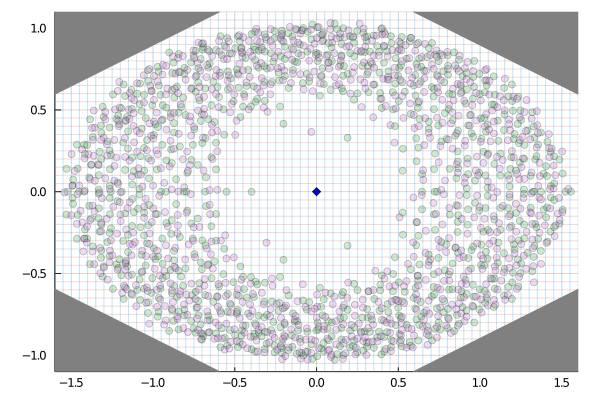

In [9]:
# xs = -1.5:0.05:2.0
# ys = -1.5:0.05:1.5
xs = -1.6:0.05:1.6
ys = -1.1:0.05:1.1

p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
scatter!(p, real(Arevs), imag(Arevs), alpha=0.25, aspect_ratio=:equal, label="")
scatter!(p, real(Acevs), imag(Acevs), alpha=0.25, aspect_ratio=:equal, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

function mask_outside_region!(p, bounds, ylims)
    for b in bounds
        if b.second === :L
            fr = ylims[1]
        elseif b.second === :U
            fr = ylims[end]
        else
            fr = nothing
        end
        plot!(p, b.first, lw=2, color=:gray, fillrange=fr, label="")
    end
    return p
end

bounds = Dict(
#     (x -> (2.8 / 5.0) * (x - 1.8)) => :L,
#     (x -> -(2.2 / 5.0) * (x - 3.4)) => :U,
#     (x -> (2.9 / 5.0) * (x + 2.6)) => :U,
    (x -> (2.5 / 5.0) * (x - 2.8)) => :L,
    (x -> -(2.5 / 5.0) * (x + 2.8)) => :L,
    (x -> -(2.5 / 5.0) * (x - 2.8)) => :U,
    (x -> (2.5 / 5.0) * (x + 2.8)) => :U,
)
mask_outside_region!(p, bounds, ys)

In [10]:
solver = create_solver(ensemble);

In [11]:
z = -1.45 + 0.50im

solution = solver(z, debug=true);

  z = -1.450 + i 0.500
-------------------------------------------------------
   γ^2        δ^2               q                k
-------------------------------------------------------
 1.48e+03   1.48e+03  -8.63e-04 + i-2.98e-04   6.74e-04
 9.85e+02   9.85e+02  -1.29e-03 + i-4.46e-04   1.01e-03
 6.56e+02   6.57e+02  -1.93e-03 + i-6.67e-04   1.51e-03
 4.37e+02   4.38e+02  -2.88e-03 + i-9.96e-04   2.26e-03
 2.91e+02   2.92e+02  -4.29e-03 + i-1.48e-03   3.37e-03
 1.94e+02   1.95e+02  -6.37e-03 + i-2.21e-03   5.02e-03
 1.29e+02   1.30e+02  -9.40e-03 + i-3.26e-03   7.44e-03
 8.60e+01   8.65e+01  -1.38e-02 + i-4.80e-03   1.10e-02
 5.72e+01   5.77e+01  -2.00e-02 + i-6.99e-03   1.61e-02
 3.80e+01   3.84e+01  -2.85e-02 + i-1.01e-02   2.33e-02
 2.52e+01   2.56e+01  -4.00e-02 + i-1.43e-02   3.34e-02
 1.67e+01   1.71e+01  -5.49e-02 + i-1.98e-02   4.71e-02
 1.10e+01   1.14e+01  -7.34e-02 + i-2.69e-02   6.53e-02
 7.20e+00   7.59e+00  -9.53e-02 + i-3.55e-02   8.86e-02
 4.68e+00   5.06e+00  -1.20e-0

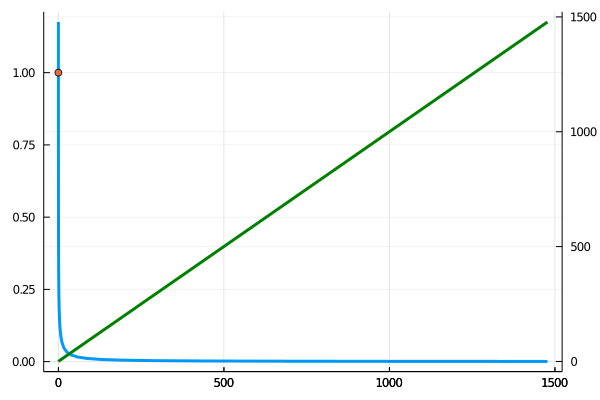

In [12]:
γsqs = [s.γsq for s in solution.trace]
δsqs = [s.δsq for s in solution.trace]
ks = [s.k for s in solution.trace]
plot(γsqs, ks, lw=3, label="")
scatter!([solution.γsq], [solution.k], label="")
plot!(twinx(), γsqs, δsqs, lw=3, color=:green, label="")

In [13]:
function in_region(x, y, bounds)
    for b in bounds
        if ((b.second === :L) && (y < b.first(x)))
            return false
        end
        if ((b.second === :U) && (y > b.first(x)))
            return false
        end
    end
    return true
end

zs = [in_region(x, y, bounds) ? complex(x, y) : complex(NaN, NaN) for y in ys, x in xs];

In [14]:
@everywhere workers() solver = create_solver($ensemble)

In [15]:
solutions = pmap(solver, WorkerPool(workers()), zs);

      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z = -1.600 + i-0.550
      From worker 2:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 2:	  z = -1.600 + i-0.500
      From worker 4:	  z =    NaN + i   NaN
      From worker 6:	  z = -1.600 + i-0.450
      From worker 8:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 4:	  z = -1.600 + i-0.400
      From worker 3:	  z =    NaN + i   NaN
      From worker 8:	  z = -1.600 + i-0.350
      From worker 5:	  z = -1.600 + i-0.300
      From worker 3:	  z = -1.600 + i-0.250
      From worker 7:	  z = -1.600 + i-0.200
      From worker 7:	  z = -1.600 + i-0.150
      From worker 7:	  z = -1.600 + i-0.100
      From worker 7:	  z = -1.600 + i-0.050
      From worker 7:	  z = -1.60

      From worker 7:	  z = -1.400 + i-0.400
      From worker 7:	  z = -1.400 + i-0.350
      From worker 7:	  z = -1.400 + i-0.300
      From worker 7:	  z = -1.400 + i-0.250
      From worker 7:	  z = -1.400 + i-0.200
      From worker 7:	  z = -1.400 + i-0.150
      From worker 7:	  z = -1.400 + i-0.100
      From worker 7:	  z = -1.400 + i-0.050
      From worker 7:	  z = -1.400 + i 0.000
      From worker 7:	  z = -1.400 + i 0.050
      From worker 7:	  z = -1.400 + i 0.100
      From worker 7:	  z = -1.400 + i 0.150
      From worker 7:	  z = -1.400 + i 0.200
      From worker 7:	  z = -1.400 + i 0.250
      From worker 7:	  z = -1.400 + i 0.300
      From worker 7:	  z = -1.400 + i 0.350
      From worker 7:	  z = -1.400 + i 0.400
      From worker 7:	  z = -1.400 + i 0.450
      From worker 7:	  z = -1.400 + i 0.500
      From worker 7:	  z = -1.400 + i 0.550
      From worker 7:	  z = -1.400 + i 0.600
      From worker 7:	  z = -1.400 + i 0.650
      From worker 7:	  z = -1.40

      From worker 7:	  z = -1.200 + i 0.150
      From worker 7:	  z = -1.200 + i 0.200
      From worker 7:	  z = -1.200 + i 0.250
      From worker 7:	  z = -1.200 + i 0.300
      From worker 7:	  z = -1.200 + i 0.350
      From worker 7:	  z = -1.200 + i 0.400
      From worker 7:	  z = -1.200 + i 0.450
      From worker 7:	  z = -1.200 + i 0.500
      From worker 7:	  z = -1.200 + i 0.550
      From worker 7:	  z = -1.200 + i 0.600
      From worker 7:	  z = -1.200 + i 0.650
      From worker 7:	  z = -1.200 + i 0.700
      From worker 7:	  z = -1.200 + i 0.750
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    Na

      From worker 7:	  z = -1.000 + i 0.750
      From worker 7:	  z = -1.000 + i 0.800
      From worker 7:	  z = -1.000 + i 0.850
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z = -0.950 + i-0.900
      From worker 7:	  z = -0.950 + i-0.850
      From worker 7:	  z = -0.950 + i-0.800
      From worker 7:	  z = -0.950 + i-0.750
      From worker 7:	  z = -0.950 + i-0.700
      From worker 7:	  z = -0.950 + i-0.650
      From worker 7:	  z = -0.950 + i-0.600
      From worker 7:	  z = -0.950 + i-0.550
      From worker 7:	  z = -0.950 + i-0.500
      From worker 7:	  z = -0.950 + i-0.450
      From worker 7:	  z = -0.95

      From worker 3:	  z = -0.750 + i 0.450
      From worker 4:	  z = -0.750 + i 0.500
      From worker 6:	  z = -0.750 + i 0.550
      From worker 7:	  z = -0.750 + i 0.600
      From worker 5:	  z = -0.750 + i 0.650
      From worker 2:	  z = -0.750 + i 0.700
      From worker 3:	  z = -0.750 + i 0.750
      From worker 4:	  z = -0.750 + i 0.800
      From worker 7:	  z = -0.750 + i 0.850
      From worker 6:	  z = -0.750 + i 0.900
      From worker 5:	  z = -0.750 + i 0.950
      From worker 2:	  z = -0.750 + i 1.000
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z = -0.700 + i-1.000
      From worker 3:	  z = -0.700 + i-0.950
      From worker 4:	  z = -0.700 + i-0.900
      From worker 7:	  z = -0.700 + i-0.850
      From worker 6:	  z = -0.700 + i-0.800
      From worker 5:	  z = -0.700 + i-0.750
      From worker 2:	  z = -0.70

...

      From worker 8:	  z =  0.400 + i 0.300
      From worker 3:	  z =  0.400 + i 0.350
      From worker 6:	  z =  0.400 + i 0.400
      From worker 7:	  z =  0.400 + i 0.450
      From worker 2:	  z =  0.400 + i 0.500
      From worker 5:	  z =  0.400 + i 0.550
      From worker 3:	  z =  0.400 + i 0.650
      From worker 4:	  z =  0.400 + i 0.600
      From worker 7:	  z =  0.400 + i 0.750
      From worker 8:	  z =  0.400 + i 0.700
      From worker 6:	  z =  0.400 + i 0.800
      From worker 7:	  z =  0.400 + i 0.850
      From worker 5:	  z =  0.400 + i 0.900
      From worker 3:	  z =  0.400 + i 0.950
      From worker 2:	  z =  0.400 + i 1.000
      From worker 4:	  z =  0.400 + i 1.050
      From worker 8:	  z =  0.400 + i 1.100
      From worker 6:	  z =  0.450 + i-1.100
      From worker 7:	  z =  0.450 + i-1.050
      From worker 5:	  z =  0.450 + i-1.000
      From worker 3:	  z =  0.450 + i-0.950
      From worker 7:	  z =  0.450 + i-0.900
      From worker 2:	  z =  0.45

      From worker 3:	  z =  0.650 + i-1.000
      From worker 7:	  z =  0.650 + i-0.950
      From worker 4:	  z =  0.650 + i-0.900
      From worker 6:	  z =  0.650 + i-0.850
      From worker 2:	  z =  0.650 + i-0.800
      From worker 5:	  z =  0.650 + i-0.750
      From worker 8:	  z =  0.650 + i-0.700
      From worker 3:	  z =  0.650 + i-0.650
      From worker 4:	  z =  0.650 + i-0.600
      From worker 7:	  z =  0.650 + i-0.550
      From worker 6:	  z =  0.650 + i-0.500
      From worker 2:	  z =  0.650 + i-0.450
      From worker 5:	  z =  0.650 + i-0.400
      From worker 3:	  z =  0.650 + i-0.350
      From worker 8:	  z =  0.650 + i-0.300
      From worker 7:	  z =  0.650 + i-0.250
      From worker 3:	  z =  0.650 + i-0.200
      From worker 4:	  z =  0.650 + i-0.150
      From worker 6:	  z =  0.650 + i-0.100
      From worker 2:	  z =  0.650 + i-0.050
      From worker 5:	  z =  0.650 + i 0.000
      From worker 8:	  z =  0.650 + i 0.050
      From worker 3:	  z =  0.65

      From worker 6:	  z =  0.850 + i 0.650
      From worker 4:	  z =  0.850 + i 0.600
      From worker 2:	  z =  0.850 + i 0.700
      From worker 8:	  z =  0.850 + i 0.750
      From worker 7:	  z =  0.850 + i 0.800
      From worker 5:	  z =  0.850 + i 0.850
      From worker 3:	  z =  0.850 + i 0.900
      From worker 4:	  z =  0.850 + i 0.950
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 2:	  z =  0.900 + i-0.900
      From worker 6:	  z =  0.900 + i-0.950
      From worker 7:	  z =  0.900 + i-0.850
      From worker 8:	  z =  0.900 + i-0.800
      From worker 5:	  z =  0.900 + i-0.750
      From worker 4:	  z =  0.900 + i-0.700
      From worker 3:	  z =  0.900 + i-0.650
      From worker 2:	  z =  0.900 + i-0.600
      From worker 4:	  z =  0.90

      From worker 8:	  z =  1.150 + i-0.550
      From worker 5:	  z =  1.150 + i-0.500
      From worker 7:	  z =  1.150 + i-0.450
      From worker 4:	  z =  1.150 + i-0.400
      From worker 2:	  z =  1.150 + i-0.350
      From worker 6:	  z =  1.150 + i-0.300
      From worker 3:	  z =  1.150 + i-0.250
      From worker 5:	  z =  1.150 + i-0.200
      From worker 8:	  z =  1.150 + i-0.100
      From worker 7:	  z =  1.150 + i-0.150
      From worker 2:	  z =  1.150 + i-0.050
      From worker 4:	  z =  1.150 + i 0.000
      From worker 6:	  z =  1.150 + i 0.050
      From worker 3:	  z =  1.150 + i 0.100
      From worker 7:	  z =  1.150 + i 0.150
      From worker 4:	  z =  1.150 + i 0.200
      From worker 5:	  z =  1.150 + i 0.250
      From worker 8:	  z =  1.150 + i 0.300
      From worker 2:	  z =  1.150 + i 0.350
      From worker 6:	  z =  1.150 + i 0.400
      From worker 7:	  z =  1.150 + i 0.450
      From worker 3:	  z =  1.150 + i 0.500
      From worker 4:	  z =  1.15

      From worker 7:	  z =  1.400 + i-0.550
      From worker 3:	  z =  1.400 + i-0.450
      From worker 6:	  z =  1.400 + i-0.500
      From worker 4:	  z =  1.400 + i-0.400
      From worker 5:	  z =  1.400 + i-0.350
      From worker 8:	  z =  1.400 + i-0.300
      From worker 2:	  z =  1.400 + i-0.250
      From worker 3:	  z =  1.400 + i-0.200
      From worker 7:	  z =  1.400 + i-0.150
      From worker 4:	  z =  1.400 + i-0.100
      From worker 5:	  z =  1.400 + i-0.050
      From worker 6:	  z =  1.400 + i 0.000
      From worker 3:	  z =  1.400 + i 0.050
      From worker 8:	  z =  1.400 + i 0.100
      From worker 2:	  z =  1.400 + i 0.150
      From worker 7:	  z =  1.400 + i 0.200
      From worker 6:	  z =  1.400 + i 0.250
      From worker 3:	  z =  1.400 + i 0.300
      From worker 5:	  z =  1.400 + i 0.350
      From worker 4:	  z =  1.400 + i 0.400
      From worker 3:	  z =  1.400 + i 0.450
      From worker 8:	  z =  1.400 + i 0.500
      From worker 2:	  z =  1.40

In [16]:
qs = similar(zs)
gsqs = similar(zs, Float64)
ks = similar(zs, Float64)

function nanclamp(x::Real, lo, hi)
    if (x < lo) || (hi < x)
        return NaN
    end
    return x
end

function nanclamp(x::Complex, relo, rehi, imlo, imhi)
    return complex(nanclamp(real(x), relo, rehi), nanclamp(imag(x), imlo, imhi))
end

trunc = 2.0
for j in 1:length(xs)
    for i in 1:length(ys)
        @inbounds begin
            s = solutions[i, j]
            gsqs[i, j] = s.γsq
            qs[i, j] = nanclamp(s.q, -trunc, trunc, -trunc, trunc)
            ks[i, j] = nanclamp(s.k, 0.0, trunc)
        end
    end
end

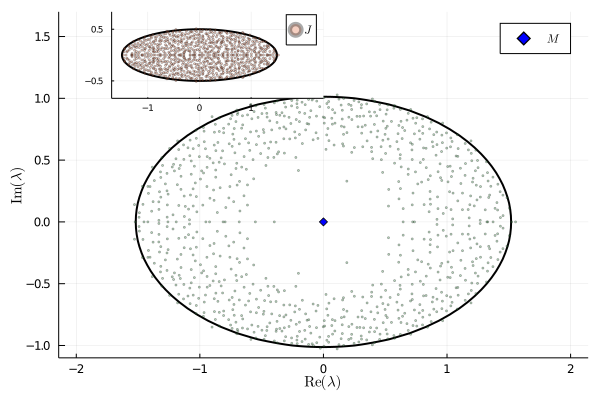

In [17]:
p = contour(
    xs,
    ys,
    gsqs,
    levels=[0.0],
    #ks,
    #levels=[1.0],
    linewidth=2,
    color=:black,
    colorbar_entry=false,
    aspect_ratio=:equal,
    #size=(270, 200),
    ylims=(ys[1], ys[end] + 0.6),
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)
scatter!(
    p,
    real(Mevs),
    imag(Mevs),
    markershape=:diamond,
    markercolor=:blue,
    aspect_ratio=:equal,
    label=L"M",
)

plot!(
    p,
    t -> (1 + τ) * cos(t),
    t -> (1 - τ) * sin(t),
    0,
    2pi,
    linewidth=2,
    color=:black,
    aspect_ratio=:equal,
    label="",
    xlims=(-1.7, 2.4),
    xticks=[-1.0; 0.0; 1.0],
    yticks=[-0.5; 0.5],
    tickfontsize=6,
    inset_subplots=(1, bbox(0.1, 0.0, 0.4, 0.25)),
    subplot=2,
)

scatter!(
    p,
    real(Arevs),
    imag(Arevs),
    #real(Acevs),
    #imag(Acevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    #label=L"M + 0.95 J",
    label="",
    subplot=1,
)

scatter!(
    p,
    real(Jrevs),
    imag(Jrevs),
    #real(Jcevs),
    #imag(Jcevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    label=L"J",
    subplot=2,
)

p

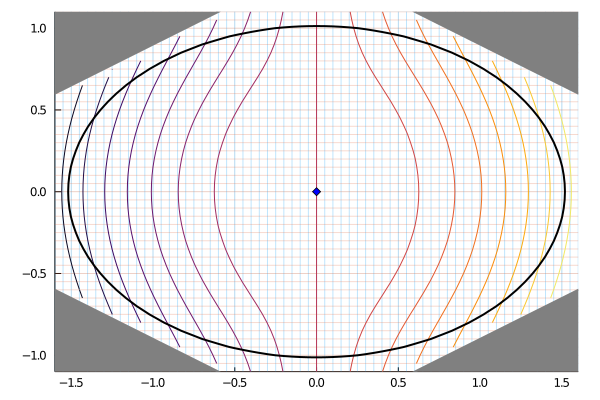

In [18]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, real(qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

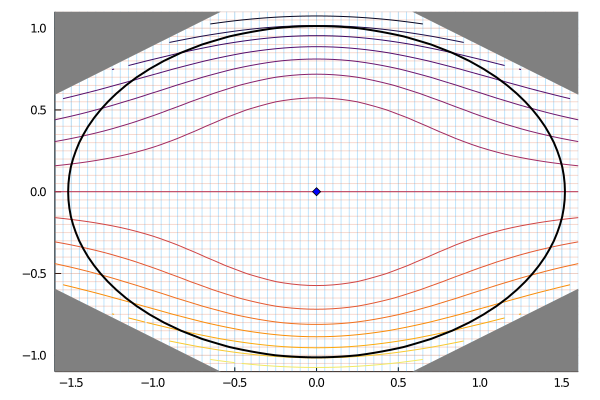

In [19]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, imag(qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

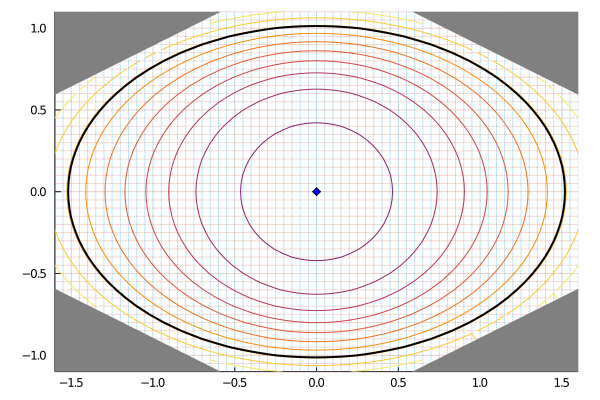

In [20]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, abs.(qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

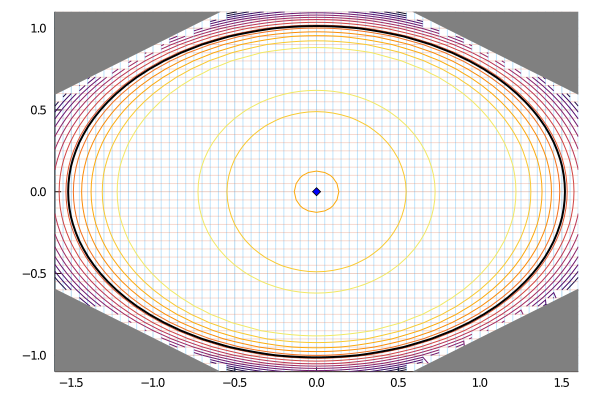

In [21]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, gsqs, aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, aspect_ratio=:equal, colorbar=false)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

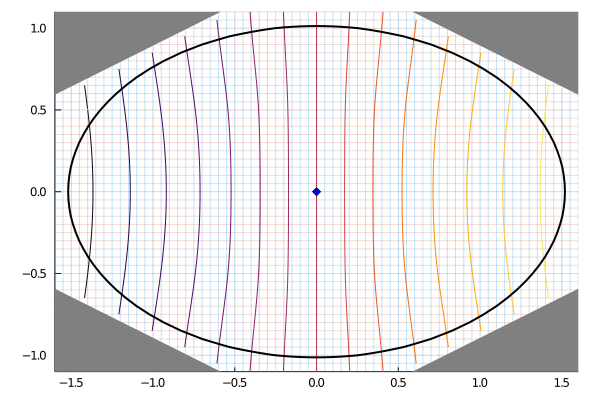

In [22]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, real((zs / σ) - sqrt(τ) * qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

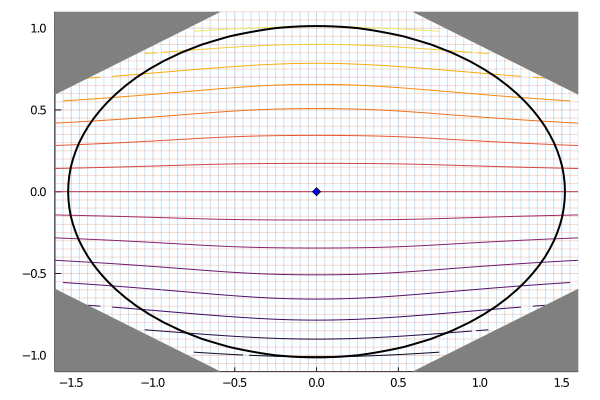

In [23]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, imag((zs / σ) - sqrt(τ) * qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

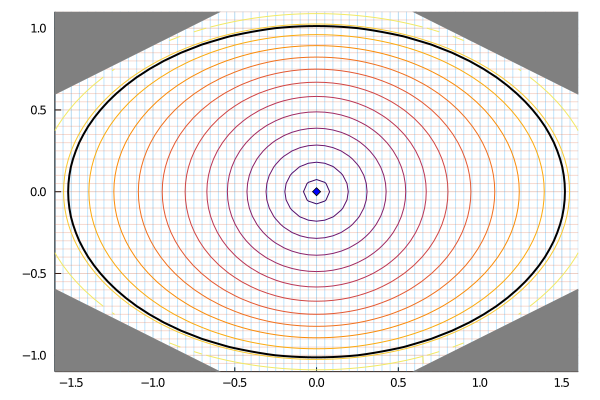

In [24]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, abs.((zs / σ) - sqrt(τ) * qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

In [25]:
# Jacobian check
ws = ComplexSpectralDensities.Workspace(ensemble)
ComplexSpectralDensities.G0_inv_and_Q_off_diag!(ws, z)
γsq = ComplexSpectralDensities.DEFAULT_ALGORITHM.rsqs[1]
q = ComplexSpectralDensities.q_asymptote(ws, γsq)
qv = [real(q); imag(q)];

In [26]:
# Analytical
Fv, Jv = zeros(2), zeros(2, 2)
ComplexSpectralDensities.residues!(Fv, Jv, ws, γsq, qv, Val(false))
Jv

2×2 Array{Float64,2}:
 -1.00034    -5.1294e-7
  5.1294e-7  -0.999663

In [27]:
# Numerical
δq = 0.001 * abs(q)
Fvδq = similar(Jv)
ComplexSpectralDensities.residues!(
    (@view Fvδq[:, 1]), nothing, ws, γsq, qv + [δq; 0.0], Val(false)
)
ComplexSpectralDensities.residues!(
    (@view Fvδq[:, 2]), nothing, ws, γsq, qv + [0.0; δq], Val(false)
)
(Fvδq .- Fv) / δq

2×2 Array{Float64,2}:
 -1.00034    -5.12939e-7
  5.1294e-7  -0.999663